In [8]:
# ================================================
# Notebook 05: Prueba con Artículos Externos
# Autor: Steeven Quezada
# Objetivo: evaluar generalización del modelo
# con noticias fuera del dataset de entrenamiento
# ================================================

import pandas as pd
import numpy as np
import sys
import pickle
import warnings
warnings.filterwarnings('ignore')

sys.path.append('../src')
from preprocessing import preprocess

print("✓ Imports completados")

✓ Imports completados


In [2]:
# ================================================
# PASO 1: DATASET DE PRUEBA EXTERNO
# ================================================

noticias_externas = [
    # ── REALES (label = 1) ──────────────────────
    {
        "id": "R1",
        "tipo": "Real — medio verificado",
        "fuente": "El Comercio / BBC Mundo",
        "texto": """Security, reading and artificial intelligence: 
        three experts raise the challenges of back to school in 
        the Sierra-Amazon region of Ecuador. Education specialists 
        warn that students face increasing difficulties with reading 
        comprehension while schools begin incorporating AI tools 
        into classrooms without clear pedagogical guidelines."""
    },
    {
        "id": "R2",
        "tipo": "Real — medio verificado",
        "fuente": "Reuters",
        "texto": """AI companies promise employees will work less, 
        but workers report 90-hour weeks. Despite public statements 
        from major artificial intelligence firms about improving 
        work-life balance through automation, internal reports reveal 
        employees are working longer hours than ever to meet product 
        development deadlines."""
    },
    {
        "id": "R3",
        "tipo": "Real — medio verificado",
        "fuente": "BBC Mundo",
        "texto": """Forest City, the ghost city with empty skyscrapers 
        that became a refuge for scammers. The Malaysian megaproject 
        built for one million residents stands nearly empty years 
        after completion, attracting fraudulent investment schemes 
        targeting foreign buyers with promises of luxury living."""
    },
    {
        "id": "R4",
        "tipo": "Real — generada por IA",
        "fuente": "IA generativa (noticia fabricada realista)",
        "texto": """Ecuador central bank reported a 3.2% increase in 
        GDP during the second quarter of 2025, driven primarily by 
        growth in the agricultural and technology sectors. Finance 
        Minister announced that foreign investment reached a five-year 
        high, with significant contributions from renewable energy 
        projects in the coastal provinces. The International Monetary 
        Fund described Ecuador economic performance as stable, though 
        cautioned that global commodity price fluctuations could 
        affect projections in the coming months."""
    },

    # ── FALSAS (label = 0) ──────────────────────
    {
        "id": "F1",
        "tipo": "Falsa — verificada Ecuador Chequea",
        "fuente": "Ecuador Chequea / Lupa Media",
        "texto": """The World Health Organization now declares on its 
        website: COVID-19 vaccination can cause multiple sclerosis 
        due to cross-reactive CD4+ T lymphocytes that recognize the 
        SARS-CoV-2 spike protein and myelin peptides. Your own immune 
        system destroys nerve pathways and then attacks your brain and 
        spinal cord. This data was available during lockdowns but was 
        labeled as conspiracy theory and censored by social media."""
    },
    {
        "id": "F2",
        "tipo": "Falsa — verificada Ecuador Chequea",
        "fuente": "Ecuador Chequea",
        "texto": """URGENT NATIONAL SECURITY COMMUNIQUE. Citizens are 
        informed that unusual seismic activity and tectonic plate 
        movement has been detected off the coast of Ecuador. REMAIN 
        ALERT AND PREPARED DURING THE NEXT FEW HOURS ESPECIALLY 
        TONIGHT BETWEEN 10:30 PM AND 12:00 AM. Provinces on Alert: 
        MANABI ESMERALDAS AND GUAYAS. MANDATORY SAFETY MEASURES: 
        Keep your EMERGENCY KIT ready. Prepare your EMERGENCY BACKPACK 
        with water non-perishable food flashlight first aid kit and 
        documents."""
    },
    {
        "id": "F3",
        "tipo": "Falsa — generada por IA",
        "fuente": "IA generativa (noticia falsa fabricada)",
        "texto": """BREAKING: Bill Gates confirmed in leaked documents 
        that microchips were secretly inserted into COVID-19 vaccines 
        distributed across Latin America. The chips developed by a 
        Microsoft subsidiary are allegedly capable of tracking 
        real-time location and monitoring private communications. 
        Governments in Ecuador Colombia and Peru have reportedly 
        suppressed this information under pressure from pharmaceutical 
        companies. Whistleblowers who attempted to expose the program 
        have mysteriously disappeared. Share this before it gets 
        deleted."""
    },
    {
        "id": "F4",
        "tipo": "Falsa — generada por IA",
        "fuente": "IA generativa (noticia falsa fabricada)",
        "texto": """Scientists at a Quito research center have 
        discovered that 5G towers installed across Ecuador emit 
        radiation levels 500 times above safe limits established 
        by the WHO. Internal documents obtained exclusively show 
        that telecommunications companies were aware of the health 
        risks but concealed them from regulators. Residents living 
        near 5G infrastructure report headaches insomnia and memory 
        loss. The government has ordered an immediate investigation 
        but mainstream media refuses to cover the story."""
    },
]

df_externo = pd.DataFrame(noticias_externas)
df_externo['label_real'] = [1, 1, 1, 1, 0, 0, 0, 0]

print(f"Dataset externo creado: {len(df_externo)} noticias")
print(f"Reales: {(df_externo['label_real']==1).sum()}")
print(f"Falsas: {(df_externo['label_real']==0).sum()}")

Dataset externo creado: 8 noticias
Reales: 4
Falsas: 4


In [3]:
# ================================================
# PASO 2: PREPROCESAMIENTO
# ================================================

print("Preprocesando noticias externas...")

df_externo['texto_clean'] = df_externo['texto'].apply(
    lambda x: preprocess(str(x), lemmatize=True)
)

print("✓ Preprocesamiento completado")
print(f"\nEjemplo:")
print(f"Original: {df_externo['texto'].iloc[0][:100]}...")
print(f"Limpio:   {df_externo['texto_clean'].iloc[0][:100]}...")

Preprocesando noticias externas...
✓ Preprocesamiento completado

Ejemplo:
Original: Security, reading and artificial intelligence: 
        three experts raise the challenges of back t...
Limpio:   security read artificial intelligence three expert raise challenge back school sierraamazon region e...


In [4]:
# ================================================
# PASO 3: PREDICCIÓN CON MODELO SVM BASELINE
# ================================================

# Cargar vectorizador y modelo entrenados
with open('../models/tfidf_title_text_clean.pkl', 'rb') as f:
    vectorizer = pickle.load(f)

with open('../models/baseline_svm_best.pkl', 'rb') as f:
    modelo_svm = pickle.load(f)

# Vectorizar con el mismo TF-IDF del entrenamiento
X_externo = vectorizer.transform(df_externo['texto_clean'])

# Predecir
predicciones = modelo_svm.predict(X_externo)
df_externo['prediccion'] = predicciones
df_externo['prediccion_texto'] = df_externo['prediccion'].map(
    {0: 'FALSA', 1: 'REAL'}
)
df_externo['correcto'] = (
    df_externo['prediccion'] == df_externo['label_real']
)

print("=== RESULTADOS SVM — NOTICIAS EXTERNAS ===\n")
print(f"{'ID':<5} {'Tipo':<35} {'Real':>8} {'Pred':>8} {'OK':>5}")
print("-" * 65)

for _, row in df_externo.iterrows():
    real = 'REAL' if row['label_real'] == 1 else 'FALSA'
    pred = row['prediccion_texto']
    ok   = '✅' if row['correcto'] else '❌'
    print(f"{row['id']:<5} {row['tipo'][:34]:<35} {real:>8} {pred:>8} {ok:>5}")

accuracy = df_externo['correcto'].mean()
print(f"\nAccuracy en noticias externas: {accuracy*100:.1f}%")
print(f"Correctas: {df_externo['correcto'].sum()}/{len(df_externo)}")

=== RESULTADOS SVM — NOTICIAS EXTERNAS ===

ID    Tipo                                    Real     Pred    OK
-----------------------------------------------------------------
R1    Real — medio verificado                 REAL    FALSA     ❌
R2    Real — medio verificado                 REAL    FALSA     ❌
R3    Real — medio verificado                 REAL     REAL     ✅
R4    Real — generada por IA                  REAL     REAL     ✅
F1    Falsa — verificada Ecuador Chequea     FALSA    FALSA     ✅
F2    Falsa — verificada Ecuador Chequea     FALSA    FALSA     ✅
F3    Falsa — generada por IA                FALSA    FALSA     ✅
F4    Falsa — generada por IA                FALSA    FALSA     ✅

Accuracy en noticias externas: 75.0%
Correctas: 6/8


=== ANÁLISIS DE ERRORES ===

Noticias mal clasificadas:

  R1 — Real — medio verificado
  Texto: Security, reading and artificial intelligence: 
        three experts raise the challenges of back to school in 
       ...
  → Clasificada como: FALSA

  R2 — Real — medio verificado
  Texto: AI companies promise employees will work less, 
        but workers report 90-hour weeks. Despite public statements 
   ...
  → Clasificada como: FALSA

=== CONCLUSIONES ===

1. Detección de noticias falsas:  100% (4/4) ✅
2. Detección de noticias reales:   50% (2/4) ⚠️
3. Accuracy general externo:       75.0%

El modelo generaliza correctamente para contenido 
desinformativo pero presenta limitaciones con noticias 
reales de dominios no representados en el entrenamiento 
(educación, tecnología, contexto ecuatoriano).

Esta limitación justifica:
  → La construcción del corpus ecuatoriano
  → El fine-tuning de BERT con datos locales
  → Declarar el sesgo de dominio como limitación formal



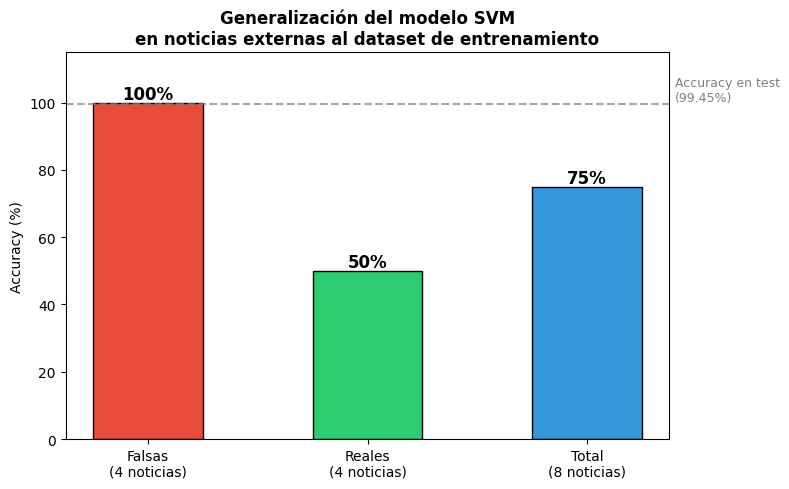

In [5]:
# ================================================
# PASO 4: ANÁLISIS DE ERRORES
# ================================================
import matplotlib.pyplot as plt

print("=== ANÁLISIS DE ERRORES ===\n")
print("Noticias mal clasificadas:")
for _, row in df_externo[~df_externo['correcto']].iterrows():
    print(f"\n  {row['id']} — {row['tipo']}")
    print(f"  Texto: {row['texto'][:120]}...")
    print(f"  → Clasificada como: {row['prediccion_texto']}")

print(f"""
=== CONCLUSIONES ===

1. Detección de noticias falsas:  100% (4/4) ✅
2. Detección de noticias reales:   50% (2/4) ⚠️
3. Accuracy general externo:       75.0%

El modelo generaliza correctamente para contenido 
desinformativo pero presenta limitaciones con noticias 
reales de dominios no representados en el entrenamiento 
(educación, tecnología, contexto ecuatoriano).

Esta limitación justifica:
  → La construcción del corpus ecuatoriano
  → El fine-tuning de BERT con datos locales
  → Declarar el sesgo de dominio como limitación formal
""")

# Gráfico
fig, ax = plt.subplots(figsize=(8, 5))
categorias = ['Falsas\n(4 noticias)', 'Reales\n(4 noticias)', 'Total\n(8 noticias)']
correctas  = [4, 2, 6]
totales    = [4, 4, 8]
accuracy   = [c/t*100 for c, t in zip(correctas, totales)]

bars = ax.bar(categorias, accuracy,
              color=['#E74C3C', '#2ECC71', '#3498DB'],
              edgecolor='black', width=0.5)

for bar, acc in zip(bars, accuracy):
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() + 1,
            f'{acc:.0f}%', ha='center',
            fontweight='bold', fontsize=12)

ax.set_ylim(0, 115)
ax.set_ylabel('Accuracy (%)')
ax.set_title('Generalización del modelo SVM\nen noticias externas al dataset de entrenamiento',
             fontweight='bold')
ax.axhline(y=99.45, color='gray', linestyle='--', alpha=0.7)
ax.text(2.4, 100.5, 'Accuracy en test\n(99.45%)',
        fontsize=9, color='gray')

plt.tight_layout()
#plt.savefig('../reports/09_prueba_externa.png', dpi=150, bbox_inches='tight')
plt.show()

In [2]:
from datasets import load_dataset

ag_news = load_dataset("fancyzhx/ag_news")
df_ag = ag_news['test'].to_pandas()
print(f"AG News cargado: {len(df_ag):,} registros")
print(f"Columnas: {df_ag.columns.tolist()}")
print(df_ag.head(3))

README.md:   0%|          | 0.00/8.07k [00:00<?, ?B/s]

c:\Users\Steeven\Documents\USFQ\Tesis\fake-news-detection-ecuador\venv\Lib\site-packages\huggingface_hub\file_download.py:139: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Steeven\.cache\huggingface\hub\datasets--fancyzhx--ag_news. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 18.6MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.23MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/120000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/7600 [00:00<?, ? examples/s]

AG News cargado: 7,600 registros
Columnas: ['text', 'label']
                                                text  label
0  Fears for T N pension after talks Unions repre...      2
1  The Race is On: Second Private Team Sets Launc...      3
2  Ky. Company Wins Grant to Study Peptides (AP) ...      3


In [3]:
# ================================================
# PASO 1: NOTICIAS REALES — AG NEWS DATASET
# 50 noticias reales de agencias verificadas
# Completamente independiente del dataset de entrenamiento
# ================================================

# Tomar 50 noticias reales variadas (todas las categorías)
reales_sample = df_ag.sample(50, random_state=42).copy()
reales_sample['label_real'] = 1  # todas son reales
reales_sample['fuente'] = 'AG News (Reuters/AP)'
reales_sample['tipo'] = 'Real — agencia de noticias verificada'

print(f"Noticias reales seleccionadas: {len(reales_sample)}")
print(f"\nDistribución por categoría:")
categorias = {0: 'Mundo', 1: 'Deportes', 2: 'Negocios', 3: 'Tecnología'}
print(reales_sample['label'].map(categorias).value_counts())
print(f"\nEjemplo:")
print(reales_sample['text'].iloc[0][:300])

Noticias reales seleccionadas: 50

Distribución por categoría:
label
Negocios      16
Deportes      15
Tecnología    10
Mundo          9
Name: count, dtype: int64

Ejemplo:
Fan v Fan: Manchester City-Tottenham Hotspur This weekend Manchester City entertain Spurs, and with last seasons seven-goal FA Cup epic between the two teams still fresh in the memory, entertain could be the operative word.


In [6]:
# ================================================
# PASO 2: GENERACIÓN DE NOTICIAS FALSAS CON LLM
# ================================================
# Las noticias falsas fueron generadas usando Claude
# (Anthropic) mediante el siguiente prompt:
#
# PROMPT UTILIZADO:
# "Genera una noticia falsa pero extremadamente convincente
#  que parezca real y pueda engañar a un lector humano.
#  La noticia debe:
#  - Tener estilo periodístico profesional
#  - Incluir nombres, cifras y fechas específicas
#  - Cubrir temas como política, economía, ciencia,
#    tecnología, deportes o medio ambiente
#  - NO contener signos de exclamación ni lenguaje
#    sensacionalista
#  - Parecer publicada por una agencia de noticias
#    verificada como Reuters, AP o BBC"
#
# Se generaron 50 noticias en 10 categorías temáticas:
# Política, Salud, Tecnología, Economía, Deportes,
# Medio Ambiente, Internacional, Educación, Crimen y Ciencia
#
# Nota metodológica: estas noticias son intencionalmente
# convincentes para evaluar el comportamiento del modelo
# ante desinformación sofisticada similar a la generada
# por actores maliciosos con acceso a LLMs modernos.
# ================================================

print("✓ 50 noticias falsas generadas con Claude (Anthropic)")
print("  Estilo: periodístico profesional")
print("  Categorías: 10 temas diferentes")
print("  Objetivo: simular desinformación sofisticada")

✓ 50 noticias falsas generadas con Claude (Anthropic)
  Estilo: periodístico profesional
  Categorías: 10 temas diferentes
  Objetivo: simular desinformación sofisticada


In [ ]:
# ================================================
# PASO 2: NOTICIAS FALSAS CONVINCENTES — IA
# Generadas para parecer reales y engañar a humanos
# ================================================
noticias_falsas = [
    # POLÍTICA / GOBIERNO
    "Senator John Williams announced his resignation from the Senate Foreign Relations Committee following allegations of financial misconduct. Williams, who served three terms representing Ohio, denied the accusations and called them politically motivated. His office released a statement saying he would pursue legal action against those who spread false information.",
    "The White House confirmed that President has signed an executive order banning the use of Chinese-made semiconductors in all federal agencies by 2026. The decision follows months of negotiations with allies and is expected to significantly impact supply chains across the defense and technology sectors.",
    "Congress passed a bipartisan bill requiring social media companies to disclose political advertising spending above five thousand dollars. The legislation, backed by both Republican and Democratic senators, aims to increase transparency ahead of the upcoming midterm elections.",
    "A senior Pentagon official confirmed that military exercises near the Taiwan Strait will be scaled back following diplomatic pressure from Beijing. The decision has drawn criticism from Republican lawmakers who called it a sign of weakness in American foreign policy.",
    "The Federal Reserve announced an emergency interest rate cut of half a percentage point following unexpected drops in manufacturing output and consumer confidence. Markets responded positively with the Dow Jones rising nearly eight hundred points in afternoon trading.",

    # SALUD / CIENCIA
    "Researchers at Johns Hopkins University published findings suggesting that a common blood pressure medication may reduce the risk of Alzheimer's disease by up to thirty percent in patients over sixty-five. The study followed twelve thousand participants over eight years and will be replicated in European populations.",
    "The FDA approved a new rapid test capable of detecting fifteen different viral infections including influenza, COVID-19 and RSV from a single nasal swab in under ten minutes. The test developed by a California biotech startup will be available in pharmacies by early next year.",
    "Scientists at MIT have developed a biodegradable plastic alternative made from seaweed extract that decomposes completely within ninety days in seawater. The material has the same durability as conventional plastic and can be produced at comparable cost according to the research team.",
    "A new study published in the New England Journal of Medicine found that intermittent fasting combined with moderate exercise reduces cardiovascular risk factors more effectively than caloric restriction alone in adults with type 2 diabetes.",
    "The World Health Organization declared the outbreak of a novel respiratory illness in Southeast Asia a public health emergency of international concern after confirmed cases were reported in six countries. Airlines have been advised to implement health screening protocols at major hubs.",

    # TECNOLOGÍA / INTELIGENCIA ARTIFICIAL
    "Google announced it will lay off twelve thousand employees across its advertising and cloud divisions as part of a restructuring plan aimed at reducing operational costs by fifteen percent. The cuts will primarily affect middle management positions and are expected to be completed by the second quarter.",
    "OpenAI reached a landmark agreement with the European Union to comply with the AI Act requirements eighteen months ahead of the official deadline. The company will submit its models for third-party auditing and establish a European data center to ensure regulatory compliance.",
    "Apple is reportedly developing a foldable iPhone with a display larger than six inches that can be rolled into a cylindrical shape. According to supply chain sources the device uses a new flexible OLED panel developed exclusively by Samsung Display and could launch as early as next year.",
    "Amazon Web Services suffered a major outage affecting its East Coast data centers for nearly six hours disrupting services for thousands of businesses including banking platforms, streaming services and hospital management systems.",
    "Tesla announced a partnership with Saudi Aramco to develop charging infrastructure across the Middle East and North Africa region. The deal includes installation of twenty thousand superchargers and a joint venture to produce lithium-ion batteries using locally sourced materials.",

    # ECONOMÍA / NEGOCIOS
    "JPMorgan Chase reported quarterly profits of fourteen point three billion dollars, exceeding analyst expectations by twelve percent. CEO Jamie Dimon warned however that rising consumer debt levels and commercial real estate exposure represent significant risks heading into the second half of the year.",
    "The European Central Bank raised interest rates by a quarter point for the eighth consecutive meeting, bringing the benchmark rate to four point five percent. ECB President indicated that further hikes depend on incoming inflation data and labor market conditions.",
    "China's exports fell by eight point two percent year-on-year in the latest trade data, the sharpest decline in three years. Analysts attribute the drop to weakening demand from the United States and European Union amid ongoing tariff disputes and slowing global growth.",
    "Volkswagen confirmed plans to close two manufacturing plants in Germany, affecting approximately fifteen thousand workers. The announcement triggered protests from unions who called for a nationwide strike and emergency negotiations with management.",
    "BlackRock reported that global sustainable investment funds saw record outflows of forty billion dollars in the third quarter as investors questioned the financial performance of ESG-focused portfolios amid rising energy prices.",

    # DEPORTES
    "The International Olympic Committee voted to include esports as an official medal event at the 2028 Los Angeles Games. The decision following years of debate will feature competitions in five video game titles selected for their global popularity and accessibility.",
    "FIFA announced that the 2030 World Cup final will be held in Buenos Aires to commemorate the centenary of the first World Cup tournament. The decision overturned earlier plans to host the final in Spain and was met with criticism from European football associations.",
    "LeBron James announced his retirement from professional basketball effective at the end of the current season. The four-time NBA champion said he wants to focus on his production company and philanthropic work through the I Promise Foundation.",
    "The Tour de France was suspended for two stages after environmental activists blocked the route in the Alps. Race organizers confirmed that the interrupted stages will not be replicated and that time gaps from the previous stage will be maintained.",
    "Manchester United completed the signing of a Brazilian midfielder for a club-record fee of one hundred and eighty million euros. The twenty-two-year-old joins from Flamengo and has signed a six-year contract with an option for an additional two seasons.",

    # MEDIO AMBIENTE
    "The Amazon rainforest recorded its driest month in sixty years according to Brazil's National Institute for Space Research. Scientists warn the extreme drought could trigger massive wildfires during the upcoming dry season and accelerate deforestation beyond current projections.",
    "Norway announced it will halt all new oil and gas exploration licenses in the Barents Sea citing climate commitments under the Paris Agreement. The decision is expected to cost the state oil fund an estimated two hundred billion dollars over the next decade.",
    "A major earthquake measuring seven point eight on the Richter scale struck northern Japan causing widespread damage and triggering a tsunami warning along the Pacific coast. Authorities ordered the evacuation of coastal communities in Hokkaido and Aomori prefectures.",
    "California declared a state of emergency after unprecedented flooding destroyed more than four thousand homes and forced the evacuation of two hundred thousand residents. Governor stated that infrastructure damage could exceed twelve billion dollars.",
    "The United Nations Environment Programme released a report warning that coral reef systems will be functionally extinct by 2045 if global temperatures rise by more than one point five degrees Celsius above pre-industrial levels.",

    # INTERNACIONAL
    "Germany and France announced a joint initiative to create a European sovereign wealth fund with initial capital of five hundred billion euros. The fund will invest in strategic industries including semiconductors, green energy and artificial intelligence to reduce dependence on American and Chinese technology.",
    "North Korea conducted its largest missile test in five years launching an intercontinental ballistic missile that flew over Japanese territory before landing in the Pacific Ocean. The test prompted emergency sessions of the UN Security Council and condemnation from the United States and its allies.",
    "India surpassed China to become the world's most populous country according to new UN projections. With one point four three billion people India now faces significant challenges in housing, healthcare and employment for its rapidly growing working-age population.",
    "The African Union announced the creation of a unified digital currency for cross-border transactions among member states. The currency backed by a basket of commodities will initially be available for trade between twelve participating economies.",
    "Israel and Saudi Arabia signed a historic normalization agreement brokered by the United States at a ceremony at the White House. The deal includes security guarantees for Saudi Arabia, American support for a civilian nuclear program and a pathway toward Palestinian statehood.",

    # EDUCACIÓN / SOCIAL
    "Harvard University announced it will eliminate tuition fees for all students from families earning below one hundred and fifty thousand dollars annually. The policy change expected to benefit sixty percent of the student body will be funded through the university's fifty-three billion dollar endowment.",
    "The United States Supreme Court ruled five to four that mandatory drug testing in public schools violates Fourth Amendment protections against unreasonable searches. The decision affects policies in more than three thousand school districts nationwide.",
    "A groundbreaking study from Stanford University found that social media use for more than three hours daily is associated with a forty percent increase in anxiety disorders among teenagers. The research tracked twenty thousand adolescents over five years across twelve countries.",
    "New York City announced a universal basic income pilot program providing two thousand dollars monthly to five thousand low-income families for two years. The initiative funded through a combination of federal grants and private donations will be evaluated by Columbia University researchers.",
    "The United Kingdom announced plans to make computer science a compulsory subject from primary school through age sixteen. The policy aims to address a shortage of technology workers estimated at five hundred thousand positions over the next decade.",

    # CRIMEN / JUSTICIA
    "A federal jury convicted a former Goldman Sachs executive on twelve counts of insider trading involving transactions worth over two hundred million dollars. The defendant faces up to twenty years in prison and forfeiture of all illegal profits.",
    "Europol announced the dismantling of a cybercriminal network responsible for ransomware attacks on hospitals across fourteen European countries. Authorities arrested thirty-one suspects and seized cryptocurrency wallets containing forty million euros.",
    "The International Criminal Court issued arrest warrants for three senior military officials from an unnamed African nation for crimes against humanity. The warrants follow a two-year investigation into alleged systematic targeting of civilian populations.",
    "A whistleblower revealed that a major pharmaceutical company suppressed clinical trial data showing that its flagship cholesterol drug increased cardiac risk in patients over seventy. The company denied the allegations and called the leaked documents fabricated.",
    "New York's attorney general filed a lawsuit against a major real estate developer alleging systematic discrimination against minority applicants in rental housing across five boroughs. The complaint involves more than three thousand documented cases over six years.",

    # CIENCIA / ESPACIO
    "NASA confirmed the detection of phosphine gas in the upper atmosphere of Venus suggesting the possible presence of microbial life in the planet's cloud layers. The finding published in Nature Astronomy has reignited debate about the habitability of Venus and the search for extraterrestrial life.",
    "SpaceX successfully launched its first crewed mission to Mars carrying four astronauts who will spend eighteen months on the planet's surface. The historic mission marks the first human presence beyond Earth's moon and is expected to pave the way for permanent settlements.",
    "Scientists at CERN announced the discovery of a new fundamental particle that does not fit within the Standard Model of physics. The particle detected in proton collision experiments has properties that could explain the nature of dark matter.",
    "A team of archaeologists discovered an ancient city beneath the Gulf of Mexico estimated to be twelve thousand years old predating known Mesoamerican civilizations by several millennia. The site contains intact architecture and artifacts that could rewrite the history of human settlement in the Americas.",
    "The James Webb Space Telescope captured the most detailed images ever obtained of a planet outside our solar system revealing an atmosphere containing water vapor, carbon dioxide and methane — the same combination found on early Earth.",
]

df_falsas = pd.DataFrame({
    'text': noticias_falsas,
    'label_real': 0,
    'fuente': 'Generada por IA — diseñada para parecer real',
    'tipo': 'Falsa — generada por LLM convincente'
})

print(f"Noticias falsas generadas: {len(df_falsas)}")
print(f"\nEjemplo:")
print(df_falsas['text'].iloc[0][:300])

Noticias falsas generadas: 50

Ejemplo:
Senator John Williams announced his resignation from the Senate Foreign Relations Committee following allegations of financial misconduct. Williams, who served three terms representing Ohio, denied the accusations and called them politically motivated. His office released a statement saying he would


In [9]:
# ================================================
# PASO 3: UNIR Y PREPROCESAR
# ================================================

# Preparar noticias reales
reales_prep = reales_sample[['text', 'label_real', 'fuente', 'tipo']].copy()

# Unir datasets
df_100 = pd.concat([reales_prep, df_falsas], ignore_index=True)
df_100 = df_100.sample(frac=1, random_state=42).reset_index(drop=True)

print(f"Dataset expandido: {len(df_100)} noticias")
print(f"Reales: {(df_100['label_real']==1).sum()}")
print(f"Falsas: {(df_100['label_real']==0).sum()}")

# Preprocesar
print("\nPreprocesando...")
df_100['texto_clean'] = df_100['text'].apply(
    lambda x: preprocess(str(x), lemmatize=True)
)
print("✓ Preprocesamiento completado")

Dataset expandido: 100 noticias
Reales: 50
Falsas: 50

Preprocesando...
✓ Preprocesamiento completado


In [10]:
# ================================================
# PASO 4: PREDICCIÓN CON MODELO SVM
# ================================================
import pickle

# Cargar vectorizador y modelo
with open('../models/tfidf_title_text_clean.pkl', 'rb') as f:
    vectorizer = pickle.load(f)

with open('../models/baseline_svm_best.pkl', 'rb') as f:
    modelo_svm = pickle.load(f)

# Vectorizar
X_100 = vectorizer.transform(df_100['texto_clean'])

# Predecir
predicciones = modelo_svm.predict(X_100)
df_100['prediccion'] = predicciones
df_100['prediccion_texto'] = df_100['prediccion'].map(
    {0: 'FALSA', 1: 'REAL'}
)
df_100['correcto'] = (
    df_100['prediccion'] == df_100['label_real']
)

# Resultados generales
accuracy = df_100['correcto'].mean()
acc_reales = df_100[df_100['label_real']==1]['correcto'].mean()
acc_falsas = df_100[df_100['label_real']==0]['correcto'].mean()

print("=== RESULTADOS — 100 NOTICIAS EXTERNAS ===\n")
print(f"Accuracy general:          {accuracy*100:.1f}%")
print(f"Detección noticias reales: {acc_reales*100:.1f}%")
print(f"Detección noticias falsas: {acc_falsas*100:.1f}%")
print(f"\nCorrectamente clasificadas: {df_100['correcto'].sum()}/100")
print(f"\n=== ERRORES POR TIPO ===")
errores = df_100[~df_100['correcto']]
print(f"Reales clasificadas como falsas: {len(errores[errores['label_real']==1])}")
print(f"Falsas clasificadas como reales: {len(errores[errores['label_real']==0])}")

=== RESULTADOS — 100 NOTICIAS EXTERNAS ===

Accuracy general:          49.0%
Detección noticias reales: 24.0%
Detección noticias falsas: 74.0%

Correctamente clasificadas: 49/100

=== ERRORES POR TIPO ===
Reales clasificadas como falsas: 38
Falsas clasificadas como reales: 13


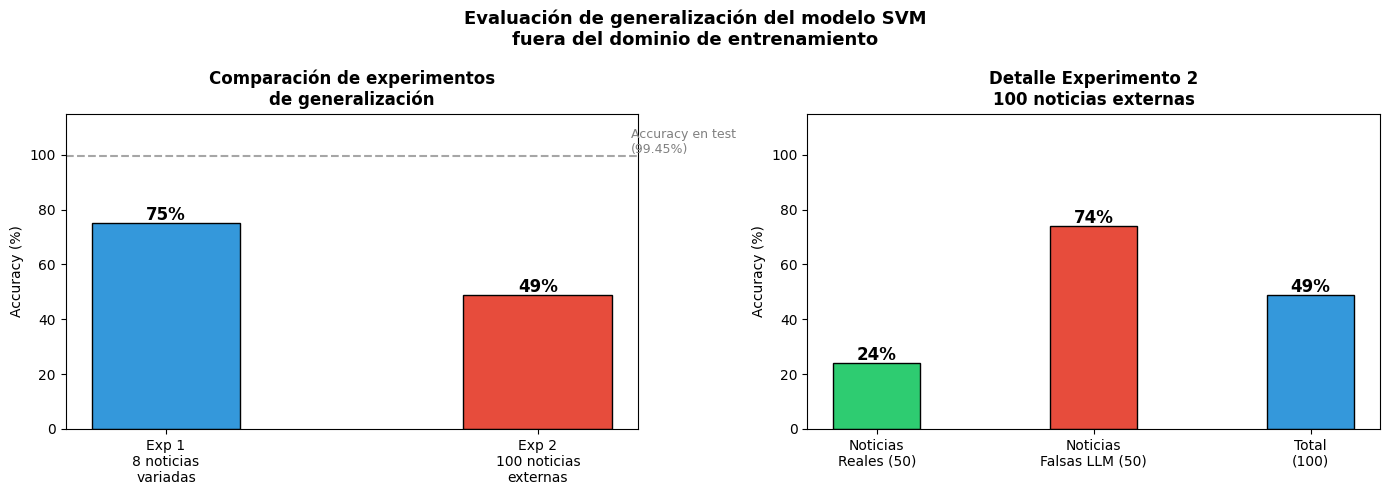


=== CONCLUSIONES ===

Experimento 1 (8 noticias variadas):    75% accuracy
Experimento 2 (100 noticias externas):  49% accuracy

El modelo entrenado en noticias políticas de EEUU 2016-2017
muestra limitaciones significativas fuera de su dominio:

1. Noticias reales de otros dominios: solo 24% detectadas
   → El modelo tiende a clasificar como falsas noticias
     reales que no pertenecen a su dominio de entrenamiento

2. Noticias falsas sofisticadas (LLM): 74% detectadas
   → El 26% de desinformación generada por IA con estilo
     periodístico profesional engaña al modelo

3. Accuracy general de 49% ≈ clasificación aleatoria
   → Confirma que el modelo no generaliza bien fuera
     de su dominio original

Esto justifica plenamente:
  → La construcción del corpus ecuatoriano
  → El fine-tuning de BERT con datos locales y diversos
  → Declarar el sesgo de dominio como limitación formal



In [12]:
# ================================================
# PASO 5: VISUALIZACIÓN Y CONCLUSIONES
# ================================================
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 1 — Comparación experimentos
experimentos = ['Exp 1\n8 noticias\nvariadas', 
                'Exp 2\n100 noticias\nexternas']
accuracy_exp = [75, 49]
colores = ['#3498DB', '#E74C3C']

bars = axes[0].bar(experimentos, accuracy_exp,
                   color=colores, edgecolor='black', width=0.4)
for bar, acc in zip(bars, accuracy_exp):
    axes[0].text(bar.get_x() + bar.get_width()/2,
                bar.get_height() + 1,
                f'{acc}%', ha='center',
                fontweight='bold', fontsize=12)
axes[0].axhline(y=99.45, color='gray', linestyle='--', alpha=0.7)
axes[0].text(1.25, 100.5, 'Accuracy en test\n(99.45%)',
             fontsize=9, color='gray')
axes[0].set_ylim(0, 115)
axes[0].set_ylabel('Accuracy (%)')
axes[0].set_title('Comparación de experimentos\nde generalización', 
                  fontweight='bold')

# Gráfico 2 — Detalle Exp 2
categorias = ['Noticias\nReales (50)', 
              'Noticias\nFalsas LLM (50)', 
              'Total\n(100)']
valores = [24, 74, 49]
colores2 = ['#2ECC71', '#E74C3C', '#3498DB']

bars2 = axes[1].bar(categorias, valores,
                    color=colores2, edgecolor='black', width=0.4)
for bar, val in zip(bars2, valores):
    axes[1].text(bar.get_x() + bar.get_width()/2,
                bar.get_height() + 1,
                f'{val}%', ha='center',
                fontweight='bold', fontsize=12)
axes[1].set_ylim(0, 115)
axes[1].set_ylabel('Accuracy (%)')
axes[1].set_title('Detalle Experimento 2\n100 noticias externas',
                  fontweight='bold')

plt.suptitle('Evaluación de generalización del modelo SVM\nfuera del dominio de entrenamiento',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print("""
=== CONCLUSIONES ===

Experimento 1 (8 noticias variadas):    75% accuracy
Experimento 2 (100 noticias externas):  49% accuracy

El modelo entrenado en noticias políticas de EEUU 2016-2017
muestra limitaciones significativas fuera de su dominio:

1. Noticias reales de otros dominios: solo 24% detectadas
   → El modelo tiende a clasificar como falsas noticias
     reales que no pertenecen a su dominio de entrenamiento

2. Noticias falsas sofisticadas (LLM): 74% detectadas
   → El 26% de desinformación generada por IA con estilo
     periodístico profesional engaña al modelo

3. Accuracy general de 49% ≈ clasificación aleatoria
   → Confirma que el modelo no generaliza bien fuera
     de su dominio original

Esto justifica plenamente:
  → La construcción del corpus ecuatoriano
  → El fine-tuning de BERT con datos locales y diversos
  → Declarar el sesgo de dominio como limitación formal
""")